# NQ Intraday Breakout — backtest

The engine lives in the [`nq_breakout`](src/nq_breakout) package; this notebook
only loads data, runs it and reports. Rules were frozen in 2022 (original
MultiCharts strategy); this Python engine is a simplified variant of it, not a
faithful port. The README lists the rules that differ.

**The cells below run both the corrected stop-fill configurations and the
actual legacy configuration.** The README reports all three, not one single
answer. The same
rules on the same data give Sharpe 1.00 under the original notebook's
conventions, 1.13 under corrected conventions with close fills and 1.00 with
stop fills. The two 1.00s are a coincidence of large offsetting effects, not
evidence that the conventions do not matter: the README attributes them one at
a time. Stop fills are the headline: they are the entry convention the
MultiCharts strategy uses.

The data file is a MultiCharts export, which stamps each minute at its *end*,
so it is loaded with `stamped_at='end'`. Reading it as bar start, as the
original notebook did, shifts every 5-minute bar by one minute.
See [`docs/bias-audit.md`](docs/bias-audit.md) for the convention differences one at
a time, and run `tools/bias_attribution.py` to reproduce the whole chain.

Before trusting any number, read the **data diagnostics** cell output: it checks
the feed's timezone, bar timestamp convention, roll splicing and overnight gap
exposure. If it reports end-stamped bars, load the file with
`load_nq_1min(..., stamped_at='end')`.

In [1]:
import pandas as pd
from dataclasses import replace
from nq_breakout import (LEGACY_CONFIG_KWARGS, LEGACY_FLAGS, Config,
                         legacy_equity_curve, load_nq_1min, load_qqq, resample_5min,
                         run_data_diagnostics, run_backtest, metrics_table,
                         format_metrics, align_benchmark, trade_pnl_tstat)
from nq_breakout.plots import plot_backtest, plot_vs_benchmark

BASE = Config()  # risk 1%, entry_mode='stop' — see backtest.Config for every knob
BASE

Config(point_value=20.0, tick_size=0.25, tick_value=5.0, stop_dollars=2000.0, target_dollars=4000.0, initial_capital=1000000.0, margin_per_contract=23282.57, margin_buffer=0.15, risk_pct=0.01, commission_per_side=2.5, slippage_ticks_per_side=1.5, slippage_sides=2, window_start=datetime.time(8, 30), window_end=datetime.time(10, 0), trade_start=datetime.time(10, 0), trade_end=datetime.time(14, 30), regular_start=datetime.time(9, 30), regular_end=datetime.time(16, 0), max_trades_per_day=2, max_long_hold_days=5, entry_mode='stop')

In [2]:
nq_1min = load_nq_1min('Data/nq-10y-1min.csv', stamped_at='end')  # MultiCharts stamps bar end
qqq = load_qqq('Data/QQQ_daily.csv')
df_5min = resample_5min(nq_1min)

run_data_diagnostics(nq_1min, BASE)

== Timezone check ==
Largest average-volume jump starts at 08:30:00 (x6.1 vs the previous half hour).
Consistent with US/Central timestamps (cash open 08:30 CT = 09:30 ET). The Config window 08:30:00-10:00:00 is therefore the first 90 minutes of the cash session. OK.

== Bar timestamp check ==
First bar after the maintenance halt is most often 17:00:00 (100% of 2510 sessions).
Consistent with bars stamped at their START, which is what the engine assumes. OK.



== Roll / splice check ==
Median |overnight gap|: 0.25 pts. Gaps beyond 20 pts: 174 (57 in quarterly roll months, 33%; ~33% expected by chance).
No roll-month clustering detected. Note this is only absence of evidence: it does not confirm the series IS back-adjusted, since a correctly adjusted series and a lightly spliced one look alike at this resolution. Confirm with the vendor.
day
2025-02-02   -371.00
2022-02-22   -366.50
2022-02-27   -287.50
2020-03-01   -198.75
2020-03-29   -165.25
2022-07-05    149.00
2022-06-21    147.50
2018-12-06   -141.00
2025-01-02    136.75
2025-01-26   -136.75

== Overnight gap risk ==
Sessions opening more than 100 pts (the stop distance) away from the prior close: 20 of 3036 (0.7%).
The feed averages 1122 bars/day — consistent with near-continuous Globex coverage. run_backtest walks every bar, including overnight ones, so stops/targets are caught at the exact crossing rather than approximated by these opening gaps.


In [3]:
bt_1pct = run_backtest(df_5min, replace(BASE, risk_pct=0.01))
bt_2pct = run_backtest(df_5min, replace(BASE, risk_pct=0.02))
legacy_config = replace(BASE, risk_pct=0.01, **LEGACY_CONFIG_KWARGS)
bt_legacy = run_backtest(df_5min, legacy_config, LEGACY_FLAGS)
legacy_equity = legacy_equity_curve(bt_legacy.trades, legacy_config.initial_capital)

for name, bt in [('1% risk, stop entry ', bt_1pct),
                 ('2% risk, stop entry ', bt_2pct),
                 ('1% risk, legacy conventions', bt_legacy)]:
    t = bt.trades
    stats = trade_pnl_tstat(t)
    print(f"{name}: {len(t):5d} trades | net PnL {t['pnl'].sum():14,.0f} | "
          f"avg contracts {t['contracts'].mean():6.2f} | "
          f"PnL/contract {stats['mean']:8.2f} (t-stat {stats['t_stat']:.2f})")

1% risk, stop entry :  1724 trades | net PnL      2,744,225 | avg contracts   8.69 | PnL/contract   176.08 (t-stat 3.22)
2% risk, stop entry :  1724 trades | net PnL     11,510,315 | avg contracts  37.03 | PnL/contract   176.08 (t-stat 3.22)
1% risk, legacy conventions:  1735 trades | net PnL      3,646,837 | avg contracts   9.74 | PnL/contract   199.34 (t-stat 3.79)


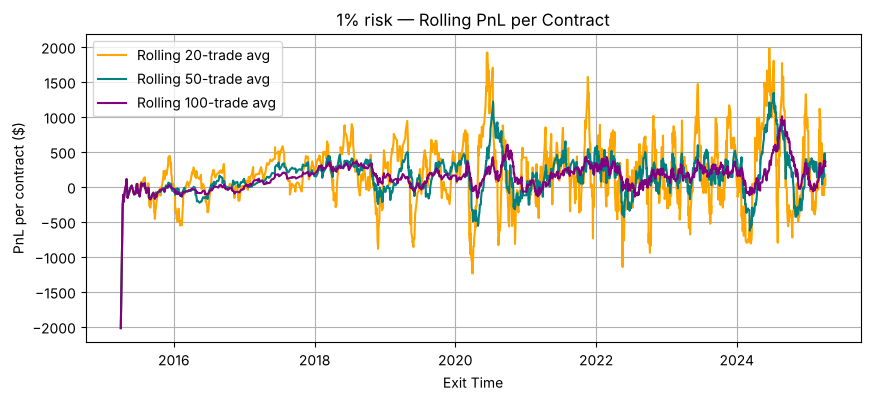

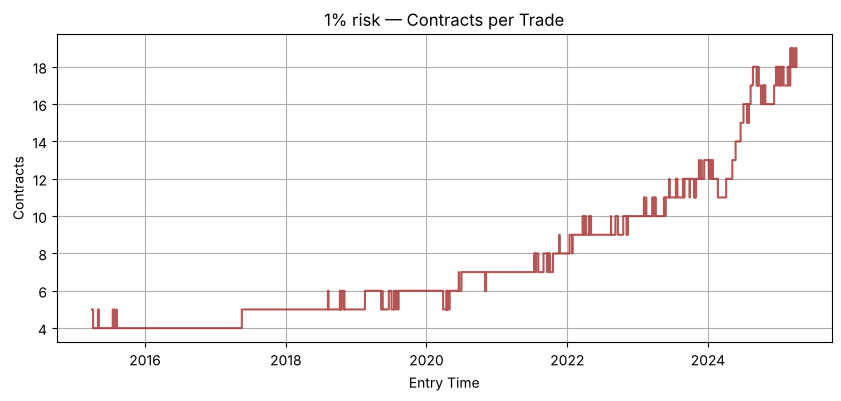

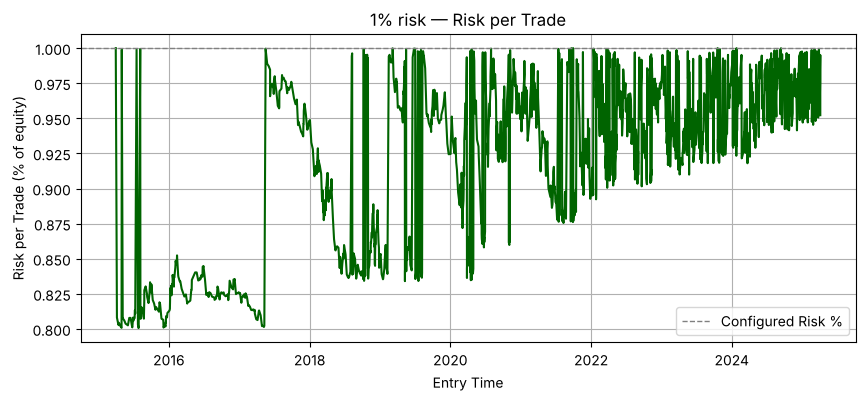

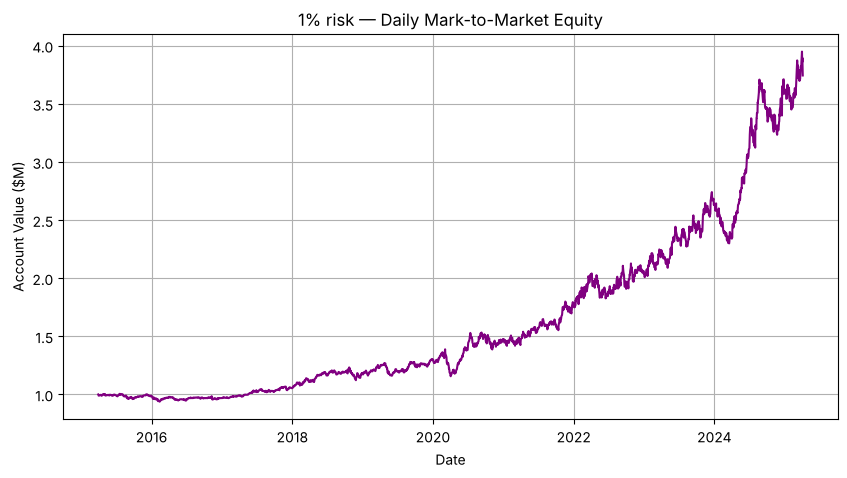

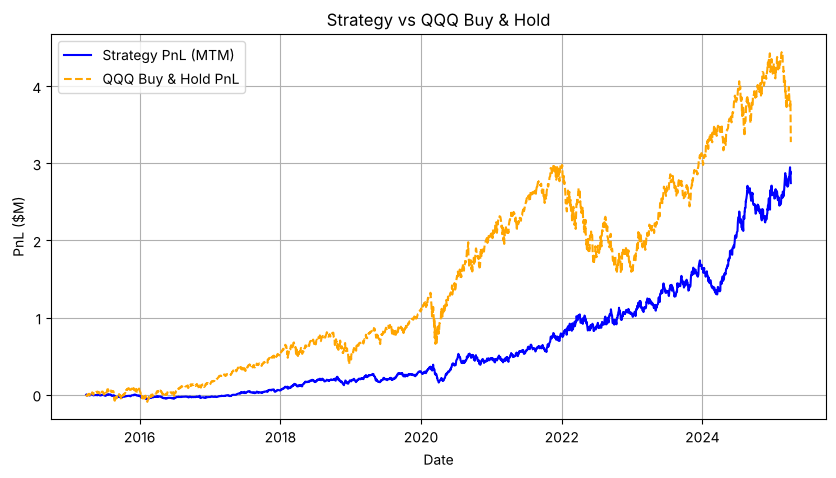

In [4]:
plot_backtest(bt_1pct, title_prefix='1% risk')

qqq_equity = align_benchmark(qqq, bt_1pct.equity.index, BASE.initial_capital)
plot_vs_benchmark(bt_1pct, qqq_equity)

In [5]:
split_date = pd.Timestamp('2022-01-31')  # rules frozen in early 2022

equities = {
    'NQ 1% risk (stop entry)': bt_1pct.equity,
    'NQ 2% risk (stop entry)': bt_2pct.equity,
    'NQ 1% risk (legacy conventions)': legacy_equity,
    'QQQ Buy & Hold': qqq_equity,
}

print("Overall (each configuration's published equity convention):")
display(format_metrics(metrics_table(equities)))

print(f'Pre-split (before {split_date.date()}):')
display(format_metrics(metrics_table({k: v[v.index < split_date] for k, v in equities.items()})))

print(f'Post-split (from {split_date.date()}):')
display(format_metrics(metrics_table({k: v[v.index >= split_date] for k, v in equities.items()})))

Overall (each configuration's published equity convention):


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ 1% risk (stop entry),1.00,14.18%,16.68%,"-474,560",14.09%
NQ 2% risk (stop entry),1.00,29.50%,32.55%,"-3,092,350",28.70%
NQ 1% risk (legacy conventions),1.00,11.24%,13.33%,"-425,745",16.58%
QQQ Buy & Hold,0.77,22.11%,35.12%,"-1,402,731",15.61%


Pre-split (before 2022-01-31):


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ 1% risk (stop entry),0.91,10.36%,16.68%,"-231,595",9.26%
NQ 2% risk (stop entry),0.90,21.77%,32.55%,"-639,240",18.84%
NQ 1% risk (legacy conventions),0.95,8.59%,11.95%,"-167,385",11.92%
QQQ Buy & Hold,0.97,21.23%,28.56%,"-663,011",20.03%


Post-split (from 2022-01-31):


,Sharpe,Volatility,Max Drawdown %,Max Drawdown $,CAGR
NQ 1% risk (stop entry),1.20,20.07%,16.09%,"-474,560",24.61%
NQ 2% risk (stop entry),1.21,41.51%,30.71%,"-3,092,350",51.31%
NQ 1% risk (legacy conventions),1.13,15.45%,13.33%,"-425,745",26.58%
QQQ Buy & Hold,0.35,23.87%,29.56%,"-1,173,939",5.63%


In [6]:
# How do the corrected stop-fill and full legacy conventions differ by direction?
comparison = pd.DataFrame({
    'stop entry': bt_1pct.trades.groupby('direction')['pnl_per_contract'].agg(['mean', 'count']).unstack(),
    'legacy conventions': bt_legacy.trades.groupby('direction')['pnl_per_contract'].agg(['mean', 'count']).unstack(),
}).round(2)
print('PnL per contract by direction and simulation convention:')
display(comparison)

PnL per contract by direction and simulation convention:


stop entry  legacy conventions
      direction                                
mean  long           332.71              411.92
      short           13.90              -20.98
count long           877.00              883.00
      short          847.00              852.00